# Evaluation and Outputs of the Boro Rice Data Engineering Pipeline

**Tasnim Ahmad Mumu** (Department of Agronomy and Agricultural Extension, University of Rajshahi) and
**Rezaul Karim** (Department of Statistics and Data Science, University of Rajshahi; corresponding author, mrkarim@ru.ac.bd)

This notebook documents the data engineering pipeline described in the paper *An open, tested data engineering
framework for integrating official crop statistics with satellite and climate data: district-level Boro rice in
Bangladesh* (submitted to *Environmental Modelling & Software*). It walks through every step of the pipeline in the
order in which it runs, explains what each step does and why, and shows the outputs that each step writes, together
with the evaluation of the framework (validation report, failure tests, reproducibility and run time). The dataset
itself is built from the original sources, step by step, in notebook `01_Data_Engineering_Pipeline.ipynb`.

The pipeline integrates three kinds of data for all 64 districts of Bangladesh and harvest years 2011–2025:

* **Official statistics**: district Boro rice area, yield and production printed in 14 editions (2012–2025) of the
  Bangladesh Bureau of Statistics (BBS) *Yearbook of Agricultural Statistics*;
* **Satellite data**: cropland NDVI (MODIS), and flood fractions from JRC monthly water history (Landsat) and
  Sentinel-1 radar;
* **Climate reanalysis**: ERA5-Land temperature and precipitation.

Every BBS value in the final panel is read from a printed table, checked against the redundancy within the
yearbooks, and traceable to its edition and page. No value is estimated, interpolated or imputed.

### How to use this notebook

* By default the notebook **reads the outputs already in the repository**, so it runs in under a minute and never
  needs the yearbook PDFs or an Earth Engine account.
* To rerun a step, set `RUN = True` in the setup cell. Rerunning the BBS extraction needs the yearbook PDFs in
  `data/bronze/bbs/pdfs/` (see the README); the Earth Engine step uses the cached extracts and contacts Earth Engine
  only for a missing or incomplete extract.
* The complete pipeline is also run from the command line with `python v2/run_all.py` (Section 16).

### Contents

1. Setup
2. Study context and data sources
3. Temporal alignment and coverage
4. Architecture
5. Step 1: extraction and validation of the BBS statistics (`s01_bbs_extract.py`)
6. Step 2: satellite and climate extraction (`s02_gee_extract.py`)
7. Step 2b: metadata manifest (`s02b_manifest.py`)
8. Step 3: Silver and Gold layers (`s03_build_panel.py`)
9. Step 3b: validation report and district crosswalk (`s03b_validate.py`)
10. Deliberate failure tests
11. Reproducibility in clean environments
12. Run time
13. Consistency of the flood variables
14. Example application
15. Dashboard
16. Rebuilding everything

## 1. Setup

The next cell finds the `v2` folder of the repository, makes the pipeline modules importable and defines two
helpers: `run()` runs a pipeline script exactly as `run_all.py` does, and `show()` displays a figure.

`RUN = False` keeps the notebook read-only. Set it to `True` to rerun the steps that have a `run(...)` call.

In [1]:
import json
import subprocess
import sys
import warnings
from pathlib import Path

import duckdb
import pandas as pd
from IPython.display import Image, Markdown, display

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

# The v2 folder is the first parent folder that contains run_all.py
V2 = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "run_all.py").exists())
SRC, OUT = V2 / "src", V2 / "outputs"
sys.path.insert(0, str(SRC))
import schema                                   # single specification of tables, checks and extraction settings
import common                                   # paths, district gazetteer and alias rules

RUN = False                                     # set to True to rerun the steps below


def run(script, *args):
    # Run a pipeline step as run_all.py does, and print the end of its output.
    p = subprocess.run([sys.executable, "-W", "ignore", script, *args], cwd=SRC,
                       capture_output=True, text=True, encoding="utf-8", errors="replace")
    print("\n".join((p.stdout + p.stderr).strip().splitlines()[-15:]))
    print(f"[exit code {p.returncode}]")


def show(name, width=900):
    display(Image(filename=str(OUT / "figures" / name), width=width))


def gold(sql):
    with duckdb.connect(str(common.V2_GOLD), read_only=True) as con:
        return con.execute(sql).df()


print("pipeline folder found:", V2.name, "| Gold database:", common.V2_GOLD.name)

pipeline folder found: v2 | Gold database: bangladesh_agri_v2.duckdb


## 2. Study context and data sources

Bangladesh is divided into **64 districts**. Boro rice, the irrigated dry-season crop, is transplanted from
December to February and harvested from late April to May; it supplies a little over half of national rice
production.

**Harvest-year convention.** A Boro season is identified by its *harvest year* $t$: the crop grown from November of
year $t-1$ to May of year $t$, which BBS reports as crop year "$(t-1)$–$t$". Crop year 2012-13 is therefore harvest
year 2013. Every table in the pipeline is keyed on harvest year, so that statistics, satellite and climate data refer
to the same season.

The table below is read from `src/schema.py`, the single specification used by every step. It lists each source,
what the product makes available, what the pipeline uses, and its licence. Two inputs are not redistributed with the
code: the BBS yearbook PDFs (download from bbs.gov.bd) and the GADM v4.1 boundaries (download from gadm.org).

In [2]:
pd.DataFrame(schema.PRODUCTS).T[["name", "available", "used", "licence"]]

,name,available,used,licence
bbs,"BBS Yearbook of Agricultural Statistics, 2012–2025 editions",each edition prints the two latest crop years,crop years 2010-11 to 2024-25 (harvest years 2011–2025),Public government statistics (PDFs not redistributed; obtain from bbs.gov.bd)
ndvi,"MODIS/061/MOD13Q1 (Terra NDVI, 16-day, 250 m)",February 2000 onward,January–April of harvest years 2011–2025,NASA open data
worldcover,ESA/WorldCover/v200 (2021),2020 and 2021 maps,2021 map as a static cropland mask,CC BY 4.0
climate,ECMWF/ERA5_LAND/DAILY_AGGR,1950 onward (about 3-month lag),November 2010 – May 2025,"Copernicus licence (free, with attribution)"
jrc,JRC/GSW1_4/MonthlyHistory (Landsat),March 1984 – December 2021,monsoon Jun–Oct 2010–2021 (harvest years 2011–2022); flash Apr–May 2011–2021 (harvest years 2011–2021); ends because...,"Copernicus programme, free with attribution"
s1,"COPERNICUS/S1_GRD (IW, VV)",over Bangladesh from 3 October 2014,flash Apr–May 2015–2025 (harvest years 2015–2025); monsoon Jun–Oct 2015–2024 (harvest years 2016–2025); the first co...,"Copernicus Sentinel data, free and open"
srtm,USGS/SRTMGL1_003,static (2000),slope mask for radar water detection,Public domain
gadm,"GADM v4.1, level 2",static,"district boundaries, areas and stable identifiers (GID_2)",Free for academic use; redistribution not permitted (users download from gadm.org)


## 3. Temporal alignment and coverage

Each satellite and climate variable is computed over a date **window** defined relative to harvest year $t$. A window
`(offset, m0, m1)` covers months `m0`–`m1` of year $t$ + `offset`; if `m0 > m1` it runs into the next year. The same
definition drives the extraction and its documentation, so they cannot disagree.

| Variable | Window for harvest year $t$ |
|---|---|
| Peak-season NDVI | January–April of $t$ |
| Temperature and precipitation | November $t-1$ to May $t$ |
| Hot days (Tmax > 35 °C) | March–May of $t$ |
| Monsoon flood fraction | June–October of $t-1$, net of January–March $t-1$ water |
| Flash flood fraction | April–May of $t$, net of January–March $t$ water |

The cell below prints the exact dates used for harvest year 2017 (end dates are exclusive).

In [3]:
rows = [{"extract": name, "window": w, "start": schema.window(2017, *spec)[0], "end (exclusive)": schema.window(2017, *spec)[1]}
        for name, e in schema.EXTRACTS.items() for w, spec in e["windows"].items()]
pd.DataFrame(rows)

,extract,window,start,end (exclusive)
0,ndvi,season,2017-01-01,2017-05-01
1,climate,season,2016-11-01,2017-06-01
2,climate,hot,2017-03-01,2017-06-01
3,jrc,monsoon,2016-06-01,2016-11-01
4,jrc,monsoon_dry,2016-01-01,2016-04-01
5,jrc,flash,2017-04-01,2017-06-01
6,jrc,flash_dry,2017-01-01,2017-04-01
7,s1,monsoon,2016-06-01,2016-11-01
8,s1,monsoon_dry,2016-01-01,2016-04-01
9,s1,flash,2017-04-01,2017-06-01


**Coverage.** Each covariate is extracted for every harvest year in which its product provides the required months,
and is left missing otherwise; series from different products are never spliced and no gap is filled. The JRC
monthly water history ends in December 2021, and Sentinel-1 data over Bangladesh begin in October 2014. The cell
below compares the declared coverage (`schema.COVERAGE`) with the values actually present in the Gold panel.

In [4]:
panel = gold("SELECT * FROM fact_boro_panel")
cov = pd.DataFrame([{"variable": v, "source": src, "declared harvest years": f"{a}–{b}",
                     "district-years expected": 64 * (b - a + 1), "district-years with values": int(panel[v].notna().sum())}
                    for v, (src, a, b) in schema.COVERAGE.items()])
cov

,variable,source,declared harvest years,district-years expected,district-years with values
0,ndvi_peak,ndvi,2011–2025,960,960
1,ndvi_max,ndvi,2011–2025,960,960
2,tmean_c,climate,2011–2025,960,960
3,tmax_c,climate,2011–2025,960,960
4,precip_mm,climate,2011–2025,960,960
5,hot_days,climate,2011–2025,960,960
6,jrc_monsoon_flood,jrc,2011–2022,768,768
7,jrc_monsoon_obs,jrc,2011–2022,768,768
8,jrc_flash_flood,jrc,2011–2021,704,704
9,jrc_flash_obs,jrc,2011–2021,704,704


Figure 1 of the paper: number of districts with observed data for each variable and harvest year.

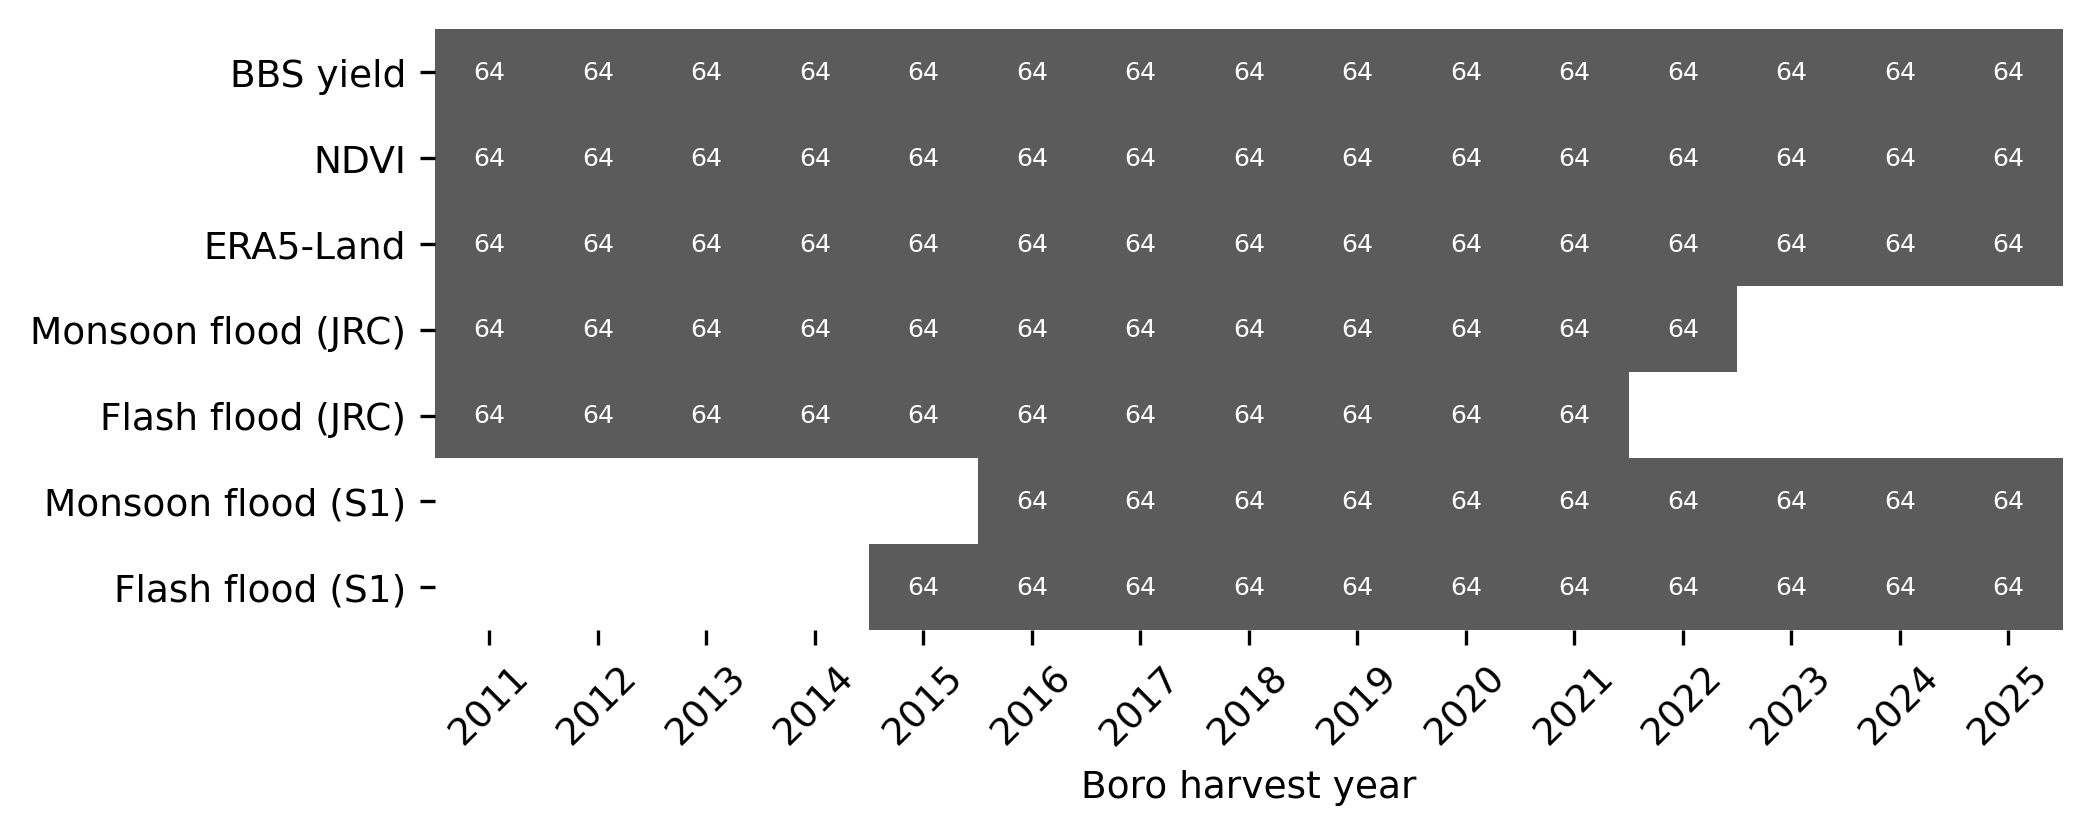

In [5]:
show("fig2_coverage.png")

## 4. Architecture

The pipeline follows a **Bronze–Silver–Gold** layering and stores the analytical tables in **DuckDB**:

* **Bronze** holds the sources as received (the yearbook PDFs and the Earth Engine district extracts), the rows parsed
  from the PDFs, and a manifest of every file;
* **Silver** holds one validated Parquet table per source, keyed on district and harvest year;
* **Gold** holds the integrated panel, the source tables it is built from, a district dimension table and national
  totals, and is read by the analyses and the dashboard.

| Step | Script | Writes |
|---|---|---|
| 1 | `s01_bbs_extract.py` | parsed BBS rows, district-year table, check files (`data/bronze/bbs/`) |
| 2 | `s02_gee_extract.py` | Earth Engine district extracts (`data/bronze/gee/`, cached per variable and year) |
| 2b | `s02b_manifest.py` | `data/bronze/manifest.csv`: versions, windows, parameters and SHA-256 of every file |
| 3 | `s03_build_panel.py` | Silver Parquet tables and the Gold DuckDB database |
| 3b | `s03b_validate.py` | validation report, district crosswalk, data dictionary |
| 4–5 | `s04_analysis.py`, `s05_figures.py` | analysis tables and figures |
| 6 | `s06_manuscript.py` | the manuscript, with every number read from the outputs |

Figure 2 of the paper shows the lineage as implemented: the files and tables written by each step and the checks
applied at each stage.

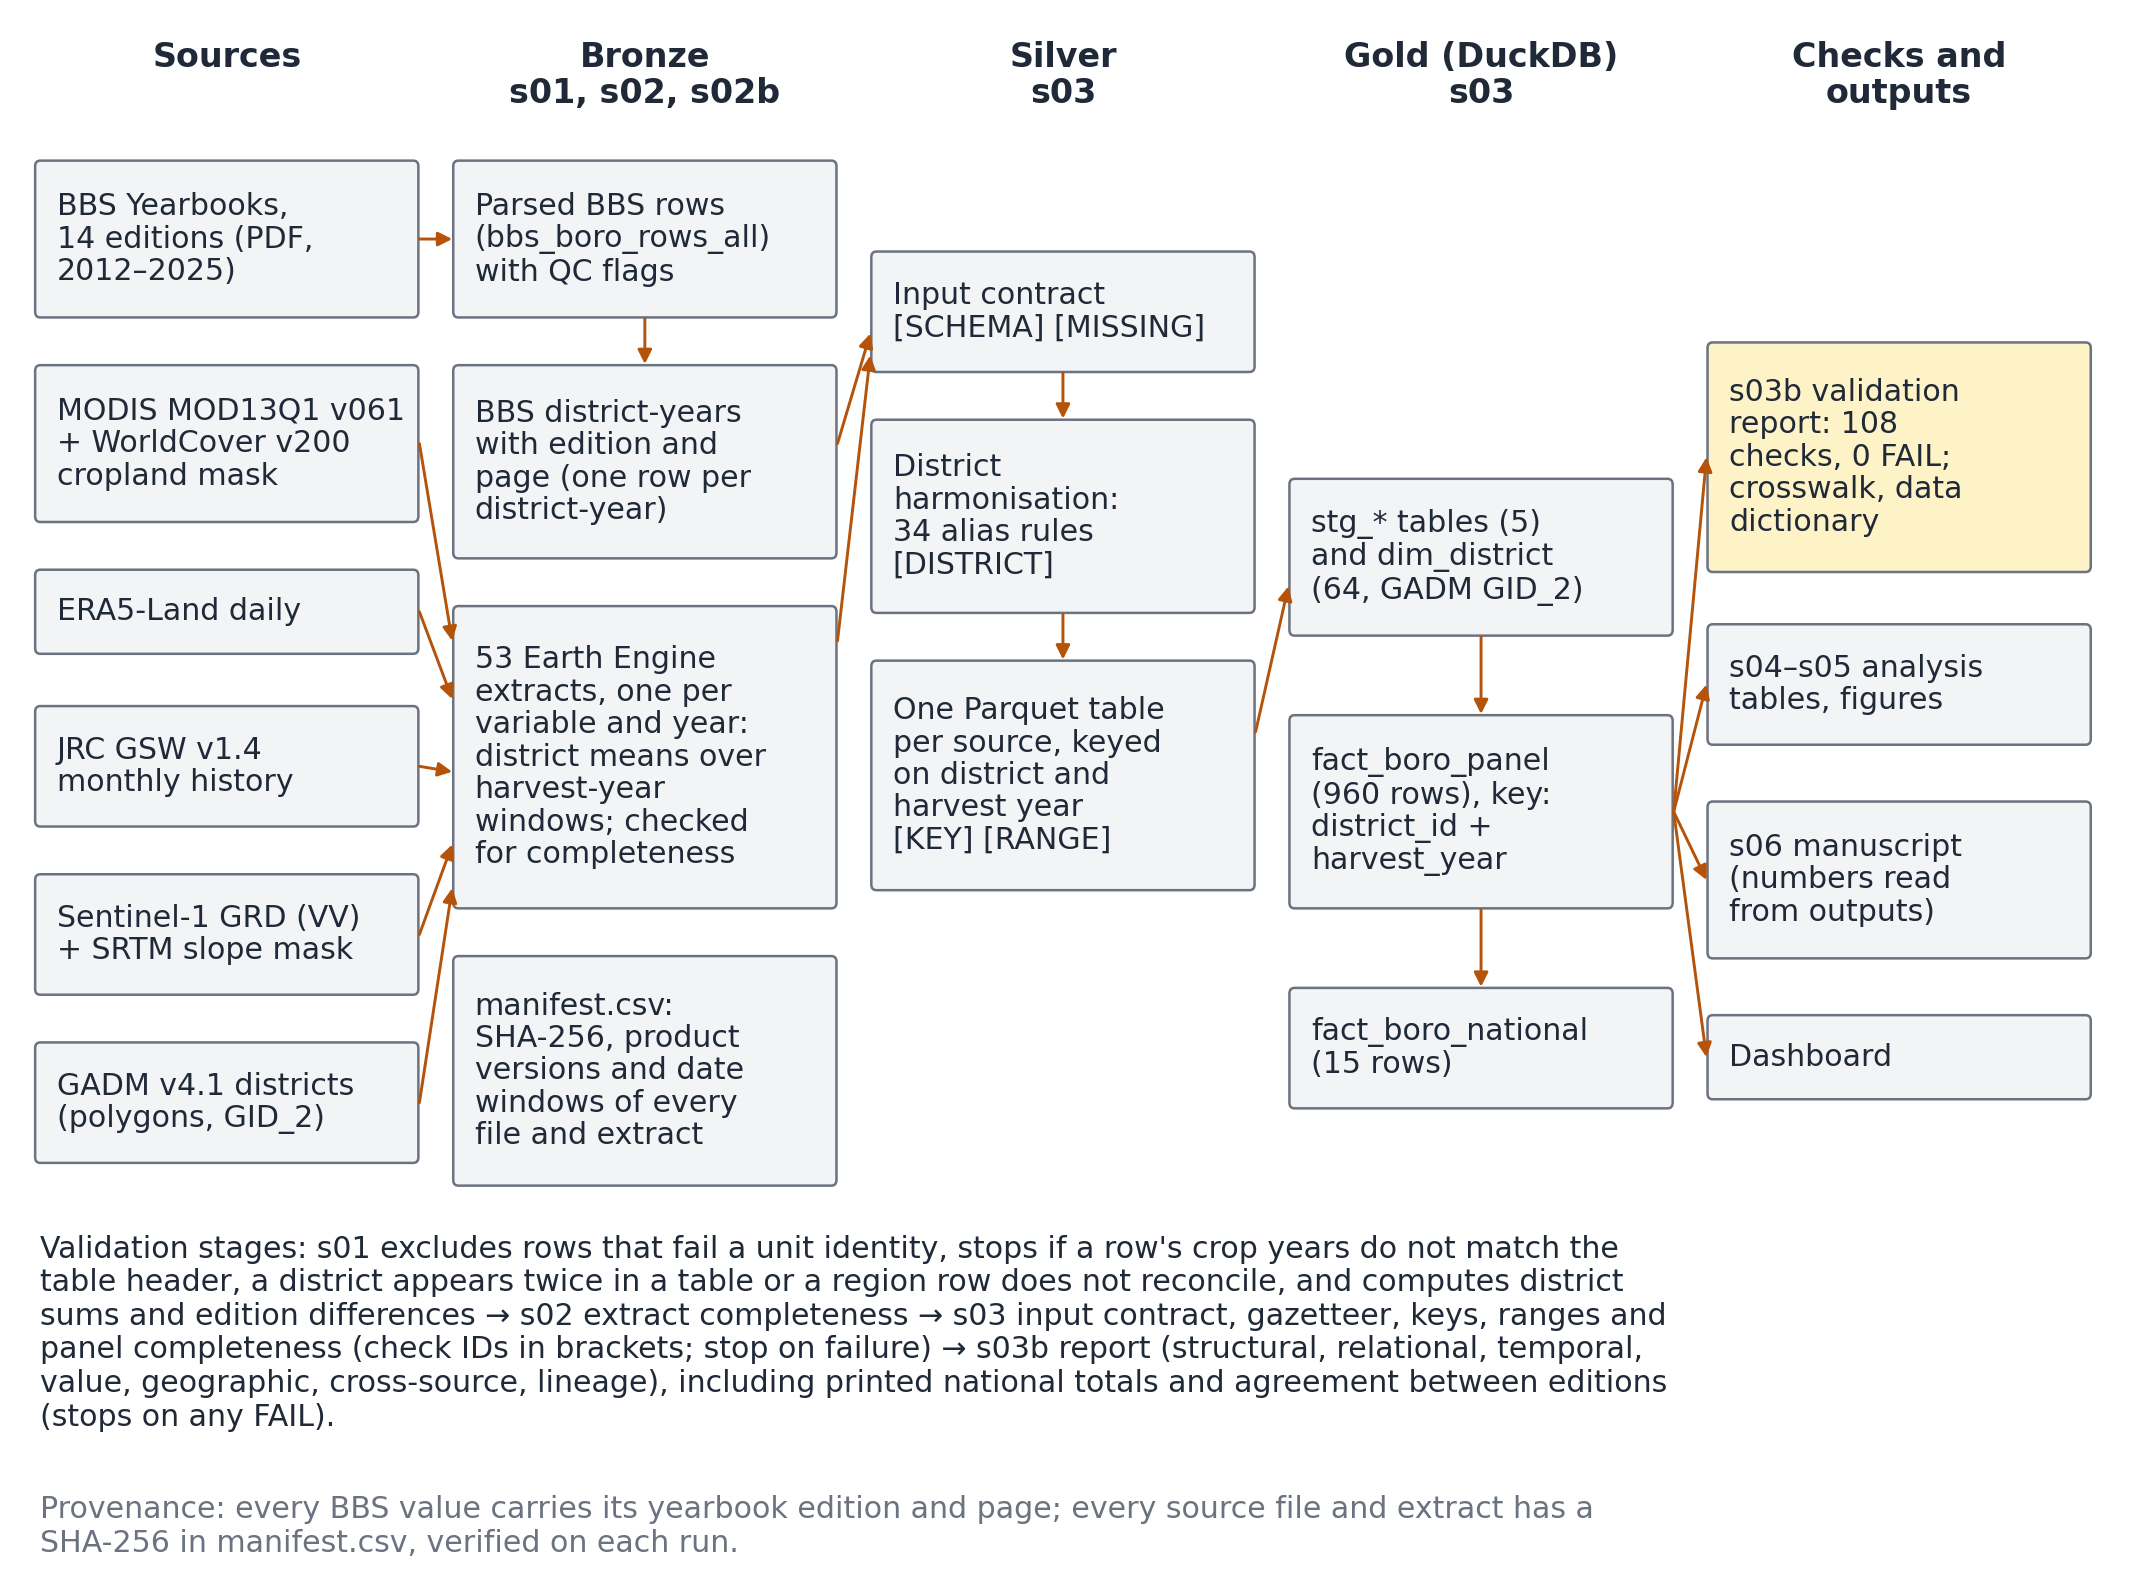

In [6]:
show("fig8_lineage.png")

## 5. Step 1: extraction and validation of the BBS statistics

**What it does.** For each of the 14 yearbook editions, the table *Estimates of Total Boro (Local + HYV + Hybrid)* is
read from the pages recorded in `schema.BBS_PAGES` with camelot (lattice mode). Each edition prints the two most
recent crop years, so crop years 2011-12 to 2023-24 appear in two editions; 2010-11 appears only in the 2012 edition
and 2024-25 only in the 2025 edition.

**Unit identities.** Each district row prints area in acres ($A_{ac}$) and hectares ($A_{ha}$), yield in maunds per
acre ($Y_{md}$) and tonnes per hectare ($Y_t$), and production in tonnes ($P$). With 1 acre = 0.404686 ha and
1 maund = 37.3242 kg, three relative discrepancies are computed:

$$E_A = \frac{|0.404686\,A_{ac} - A_{ha}|}{A_{ha}}, \qquad
  E_Y = \frac{|0.0373242\,Y_{md}/0.404686 - Y_t|}{Y_t}, \qquad
  E_P = \frac{|A_{ha}\,Y_t - P|}{P}.$$

A row is accepted only if all three are at most 0.5 %. Failing rows are excluded and logged; no value is edited by
hand.

**Further checks.** The district sum of each complete table is compared with the national total printed in it (or,
for the two crop years whose tables print none, with the total quoted in the yearbook text). Where a crop year is
printed in two editions the two rows are compared, and the later edition is used. The 2012 and 2013 editions group
districts under former regions; their region rows are reconciled with the district rows (Section 5.4).

In [7]:
if RUN:
    run("s01_bbs_extract.py")      # needs the yearbook PDFs; about 1.5 minutes

bbs = common.V2_BRONZE / "bbs"
rows = pd.read_csv(bbs / "bbs_boro_rows_all.csv")
print("rows parsed by type:", rows.row_type.value_counts().to_dict())
rows[(rows.district == "Rajshahi") & rows.crop_year.isin(["2019-20", "2020-21"])][
    ["book_year", "page", "crop_year", "area_acres", "area_ha", "yield_maund_acre", "yield_t_ha", "production_t",
     "qc_ha", "qc_yield", "qc_prod", "qc_pass"]]

rows parsed by type: {'district': 1726, 'division': 218, 'national': 22}


,book_year,page,crop_year,area_acres,area_ha,yield_maund_acre,yield_t_ha,production_t,qc_ha,qc_yield,qc_prod,qc_pass
1241,2020,93,2019-20,163475.0,66155.0,41.73,3.85,254667.0,0.000016,0.000322,0.000117,True
1378,2021,99,2019-20,163475.0,66155.0,41.73,3.85,254667.0,0.000016,0.000322,0.000117,True
1379,2021,99,2020-21,161465.0,65341.0,44.02,4.06,265300.0,0.000025,0.000008,0.000059,True
1510,2022,99,2020-21,161465.0,65341.0,44.02,4.06,265300.0,0.000025,0.000008,0.000059,True


The same district-year printed in two editions (above: Rajshahi 2019-20 in the 2020 and 2021 editions) gives the
same values, and every identity discrepancy (`qc_*`) is far below 0.5 %. The cell below recomputes the three
identities by hand for one row, using only the printed numbers.

In [8]:
r = rows[(rows.district == "Rajshahi") & (rows.crop_year == "2019-20") & (rows.book_year == 2021)].iloc[0]
E_A = abs(0.404686 * r.area_acres - r.area_ha) / r.area_ha
E_Y = abs(0.0373242 * r.yield_maund_acre / 0.404686 - r.yield_t_ha) / r.yield_t_ha
E_P = abs(r.area_ha * r.yield_t_ha - r.production_t) / r.production_t
print(f"E_A = {100 * E_A:.3f} %   E_Y = {100 * E_Y:.3f} %   E_P = {100 * E_P:.3f} %   (limit 0.5 %)")

E_A = 0.002 %   E_Y = 0.032 %   E_P = 0.012 %   (limit 0.5 %)


### 5.1 Rows that fail an identity

These rows are excluded and logged; the same district-years are taken from the other edition.

In [9]:
pd.read_csv(bbs / "bbs_qc_failures.csv")[["book_year", "crop_year", "district", "yield_maund_acre", "yield_t_ha",
                                          "qc_ha", "qc_yield", "qc_prod", "failed_checks"]]

,book_year,crop_year,district,yield_maund_acre,yield_t_ha,qc_ha,qc_yield,qc_prod,failed_checks
0,2013,2012-13,Shariatpur,46.89,4.171,0.000010,0.036841,0.000092,yield
1,2013,2012-13,Magura,47.16,3.727,0.000019,0.167043,0.000068,yield
2,2013,2012-13,Narail,46.30,4.169,0.000014,0.024286,0.000032,yield
3,2013,2012-13,Sirajganj,46.48,4.157,0.000018,0.031237,0.000115,yield


### 5.2 District sums against the printed national totals

One row per edition and crop year: the number of districts parsed, the district sum of production, the printed
national total and the gap. The gap is evaluated only for complete tables (64 districts); in the 2015 and 2018
editions part of the table did not parse, and those crop years are complete in the other edition.

In [10]:
pd.read_csv(bbs / "bbs_edition_checks.csv")[["book_year", "crop_year", "n_districts", "n_qc_fail", "sum_prod",
                                             "national_prod", "prod_gap_pct"]]

,book_year,crop_year,n_districts,n_qc_fail,sum_prod,national_prod,prod_gap_pct
0,2012,2010-11,64,0,1.861678e+07,NaN,NaN
1,2012,2011-12,64,0,1.875921e+07,NaN,NaN
2,2013,2011-12,64,0,1.875921e+07,18759212.0,0.000005
3,2013,2012-13,64,4,1.877816e+07,18778154.0,0.000005
4,2014,2012-13,64,0,1.877816e+07,18778154.0,0.000005
5,2014,2013-14,64,0,1.900720e+07,19007206.0,-0.000016
6,2015,2013-14,63,0,1.832469e+07,19007206.0,-3.590817
7,2015,2014-15,63,0,1.846225e+07,19192164.0,-3.803167
8,2016,2014-15,64,0,1.919217e+07,19192164.0,0.000010
9,2016,2015-16,64,0,1.893758e+07,18937581.0,-0.000021


### 5.3 Years printed in two editions

District-years whose area or yield differ between the two editions that print them (differences of 1 ha are rounding).

In [11]:
pd.read_csv(bbs / "bbs_edition_diffs.csv")

,district,crop_year,early_book,late_book,early_yield,late_yield,early_area,late_area
0,Dinajpur,2013-14,2014,2015,4.114,4.114,174484.0,174485.0
1,Jashore,2013-14,2014,2015,4.118,4.118,158817.0,158818.0
2,Kurigram,2013-14,2014,2015,4.235,4.235,96923.0,96924.0
3,Meherpur,2013-14,2014,2015,3.986,3.986,21791.0,21792.0
4,Narail,2013-14,2014,2015,3.511,3.511,34586.0,34585.0
5,Satkhira,2013-14,2014,2015,3.814,3.814,75335.0,75334.0


### 5.4 Region rows of the 2012 and 2013 editions

Each multi-district region row must equal the sum of the district rows listed under it, and each of the five
single-district region rows must equal the district row printed for the same crop year (2012-13) in the
district-structured 2014 edition. Only then are those rows used as estimates for the present-day districts.

In [12]:
reg = pd.read_csv(bbs / "bbs_region_checks.csv")
print(reg.groupby("check").match.agg(["size", "sum"]).rename(columns={"size": "rows", "sum": "match"}))
reg[reg.check.str.startswith("single")][["unit", "districts", "region_area_ha", "compare_area_ha",
                                         "region_production_t", "compare_production_t", "match"]]

                                            rows  match
check                                                  
region = sum of listed districts              72     72
single-district region = 2014 district row     5      5


,unit,districts,region_area_ha,compare_area_ha,region_production_t,compare_production_t,match
72,Bandarban Region [single-district region],Bandarban,3227.0,3227.0,9650.0,9650.0,True
73,Khagrachari Region [single-district region],Khagrachhari,10272.0,10272.0,33326.0,33326.0,True
74,Rangamati Region [single-district region],Rangamati,4788.0,4788.0,16623.0,16623.0,True
75,Mymenshing Region [single-district region],Mymensingh,262040.0,262040.0,936015.0,936015.0,True
76,Tangail Region [single-district region],Tangail,163636.0,163636.0,658469.0,658469.0,True


### 5.5 The BBS district-year table

The result is one row per district and crop year, taken from the later edition among rows that pass the identities,
with the edition and page of every value. It has 64 districts × 15 seasons = 960 rows and no missing value.

In [13]:
dy = pd.read_csv(bbs / "bbs_boro_district_year.csv")
print(len(dy), "district-years;", dy.district.nunique(), "districts;", dy.harvest_year.nunique(), "harvest years")
dy[["district", "crop_year", "harvest_year", "area_ha", "yield_t_ha", "production_t", "book_year", "page"]].head()

960 district-years; 64 districts; 15 harvest years


,district,crop_year,harvest_year,area_ha,yield_t_ha,production_t,book_year,page
0,Bagerhat,2010-11,2011,45561.0,3.311,150872.0,2012,91
1,Bandarban,2010-11,2011,3295.0,2.871,9459.0,2012,90
2,Barguna,2010-11,2011,439.0,2.183,958.0,2012,91
3,Barishal,2010-11,2011,60520.0,3.765,227852.0,2012,91
4,Bhola,2010-11,2011,56213.0,3.484,195826.0,2012,91


## 6. Step 2: satellite and climate extraction

**What it does.** For every product and harvest year, `s02_gee_extract.py` computes each variable per pixel in Google
Earth Engine (a seasonal mean, total, count or maximum; for flood, a classification as seasonally inundated or not)
and averages it over each GADM district polygon. NDVI and the climate variables are therefore district means of
seasonal aggregates, and the flood variables are the proportion of district area classified as seasonally inundated.

**Caching and completeness.** Each extract is saved as `data/bronze/gee/<product>_<year>.csv`. Before an extract is
used or cached it must contain all 64 districts and a non-missing value of every variable its product should provide
for that year; an incomplete extract is recomputed rather than reused. The date each extract was computed is kept in
`extraction_dates.json` and copied into the manifest.

The extraction settings below are read from `schema.EXTRACTS`.

In [14]:
pd.DataFrame(schema.EXTRACTS).T[["collection", "version", "bands", "scale_m", "mask", "method"]]

,collection,version,bands,scale_m,mask,method
ndvi,MODIS/061/MOD13Q1,Collection 6.1 (061),"NDVI, SummaryQA",250,ESA/WorldCover/v200 (2021) class 40 covering > 50 % of the MODIS cell; SummaryQA ≤ 1,mean (ndvi_peak) and maximum (ndvi_max) of the 16-day composites in the window; district mean over masked pixels
climate,ECMWF/ERA5_LAND/DAILY_AGGR,ERA5-Land daily aggregates,"temperature_2m, temperature_2m_max, total_precipitation_sum",1000,none (land-only product),season mean of daily mean and daily maximum temperature; season total precipitation; number of days with daily maxim...
jrc,JRC/GSW1_4/MonthlyHistory,v1.4,water,30,none,water (class 2) in any month of the window and not water in any month of the matching dry window; share of district ...
s1,COPERNICUS/S1_GRD,"GRD, IW mode, VV polarisation",VV,60,slope < 5° from USGS/SRTMGL1_003,"monthly median VV, 50 m focal median, water if < −18 dB; water in any month of the window and not water in the dry-w..."


In [15]:
from s02_gee_extract import expected_columns, complete     # importing does not contact Earth Engine

for year in [2015, 2016]:
    print(year, "Sentinel-1 variables expected:", expected_columns("s1", year))
s1 = pd.read_csv(common.V2_BRONZE / "gee" / "s1_2017.csv")
print("s1_2017.csv complete:", complete(s1, "s1", 2017))
s1.sort_values("s1_flash_flood", ascending=False).head()

2015 Sentinel-1 variables expected: ['s1_flash_flood']
2016 Sentinel-1 variables expected: ['s1_monsoon_flood', 's1_flash_flood']
s1_2017.csv complete: True


,district,s1_flash_flood,s1_monsoon_flood,harvest_year
62,Sunamganj,0.447092,0.524391,2017
21,Kishoreganj,0.270001,0.473809,2017
42,Netrokona,0.173941,0.355064,2017
63,Sylhet,0.126921,0.238719,2017
60,Habiganj,0.102023,0.174892,2017


In harvest year 2015 only the flash-flood window (April–May 2015) is covered by Sentinel-1; the first complete
monsoon season is June–October 2015, which belongs to harvest year 2016. The completeness test therefore expects one
Sentinel-1 variable in 2015 and two from 2016.

In [16]:
times = json.loads((common.V2_BRONZE / "gee" / "extraction_times.json").read_text())
t = pd.Series(times).rename("seconds").to_frame()
t["product"] = t.index.str.rsplit("_", n=1).str[0]
t.groupby("product").seconds.agg(["count", "mean"]).round(0).rename(columns={"count": "extracts", "mean": "mean seconds per year"})

,extracts,mean seconds per year
product,,
climate,14,21.0
jrc,11,201.0
ndvi,14,35.0
s1,10,111.0


## 7. Step 2b: metadata manifest

`s02b_manifest.py` writes one row per source file and extract: the product and version, the exact date windows used
for that harvest year, the spatial scale, mask, method and parameters, the variables present, the number of rows, the
extraction date and the SHA-256 checksum. The validation step recomputes every checksum on each run, so a file that
changes after the manifest was written is detected. Users can also confirm that their downloaded yearbook PDFs are
the files used: after a run, `git diff v2/data/bronze/manifest.csv` is empty if they are.

In [17]:
import hashlib

man = pd.read_csv(common.V2_BRONZE / "manifest.csv")
print(man.kind.value_counts().to_string())
row = man[man.kind == "Earth Engine extract"].iloc[0]
f = V2 / row.file[3:]
print("\nchecksum of", row.file, "matches the manifest:", hashlib.sha256(f.read_bytes()).hexdigest() == row.sha256)
man[man.kind == "Earth Engine extract"][["file", "product", "windows", "scale_m", "parameters", "extracted_utc"]].head(4)

kind
Earth Engine extract    53
BBS yearbook PDF        14
GADM boundaries         10

checksum of v2/data/bronze/gee/ndvi_2011.csv matches the manifest: True


,file,product,windows,scale_m,parameters,extracted_utc
24,v2/data/bronze/gee/ndvi_2011.csv,MODIS/061/MOD13Q1,season 2011-01-01 to 2011-05-01 (exclusive),250.0,NaN,2026-10-25
25,v2/data/bronze/gee/ndvi_2012.csv,MODIS/061/MOD13Q1,season 2012-01-01 to 2012-05-01 (exclusive),250.0,NaN,2026-10-25
26,v2/data/bronze/gee/ndvi_2013.csv,MODIS/061/MOD13Q1,season 2013-01-01 to 2013-05-01 (exclusive),250.0,NaN,2026-10-25
27,v2/data/bronze/gee/ndvi_2014.csv,MODIS/061/MOD13Q1,season 2014-01-01 to 2014-05-01 (exclusive),250.0,NaN,2026-10-25


## 8. Step 3: Silver and Gold layers

**Input contract.** Before any table is built, every Bronze file is checked against the specification: required
columns present, numeric columns numeric (a text entry such as "n/a" is an error, not a missing value), and BBS
area, yield and production present in every row. District names are mapped to the gazetteer of 64 districts; a name
that matches neither a canonical name nor an alias rule stops the run. A violated rule raises an error whose message
starts with a check identifier and names the file, column and records involved:

| Check ID | Meaning |
|---|---|
| `[SCHEMA]` | missing required column, or non-numeric value in a numeric column |
| `[MISSING]` | empty BBS value, or a district-year without a BBS value in the panel |
| `[DISTRICT]` | district name not in the gazetteer or the alias table |
| `[KEY]` | duplicate district and harvest year |
| `[RANGE]` | value outside its declared plausible range |

**Data model.** The Gold database holds eight tables. The panel, `fact_boro_panel`, has one row per district and
harvest year, keyed on a stable district identifier (`district_id`, the GADM GID_2 code) and the harvest year.

In [18]:
if RUN:
    run("s03_build_panel.py")

tables = gold("SHOW TABLES").name
pd.DataFrame({"table": tables, "rows": [int(gold(f"SELECT count(*) AS n FROM {t}").n[0]) for t in tables],
              "grain": [schema.TABLES.get(t, {}).get("grain", "") for t in tables]})

,table,rows,grain
0,dim_district,64,one row per district
1,fact_boro_national,15,one row per harvest year
2,fact_boro_panel,960,one row per district and harvest year
3,stg_bbs_boro,960,one row per district and harvest year
4,stg_climate,960,one row per district and harvest year
5,stg_jrc,768,one row per district and harvest year
6,stg_ndvi,960,one row per district and harvest year
7,stg_s1,704,one row per district and harvest year


In [19]:
spec = schema.TABLES["fact_boro_panel"]
print("key:", spec["key"], "| rows:", spec["rows"], "| source:", spec["source"])
pd.DataFrame(spec["columns"], columns=["column", "type", "unit", "description"])

key: ['district_id', 'harvest_year'] | rows: 960 | source: stg_bbs_boro joined to dim_district and the covariate staging tables


,column,type,unit,description
0,district_id,VARCHAR,,GADM v4.1 GID_2
1,district,VARCHAR,,Canonical district name (64-district gazetteer)
2,division,VARCHAR,,Administrative division
3,area_km2,DOUBLE,km²,District area
4,harvest_year,BIGINT,year,Boro harvest year t (crop grown Nov t−1 – May t)
5,crop_year,VARCHAR,,BBS crop year
6,yield_t_ha,DOUBLE,t/ha,Boro yield (husked rice)
7,area_ha,DOUBLE,ha,Harvested Boro area
8,production_t,DOUBLE,t,Boro production (husked rice)
9,bbs_edition,BIGINT,year,Source yearbook edition


In [20]:
panel[panel.district == "Sunamganj"][["district_id", "district", "harvest_year", "yield_t_ha", "area_ha", "production_t",
                                      "bbs_edition", "bbs_page", "ndvi_peak", "jrc_flash_flood", "s1_flash_flood"]].head(8)

,district_id,district,harvest_year,yield_t_ha,area_ha,production_t,bbs_edition,bbs_page,ndvi_peak,jrc_flash_flood,s1_flash_flood
900,BGD.7.3_1,Sunamganj,2011,3.448,190662.0,657326.0,2012,90,0.526193,0.001990,NaN
901,BGD.7.3_1,Sunamganj,2012,3.407,188786.0,643271.0,2013,92,0.499222,0.105823,NaN
902,BGD.7.3_1,Sunamganj,2013,3.367,190525.0,641455.0,2014,90,0.508718,0.213900,NaN
903,BGD.7.3_1,Sunamganj,2014,3.488,186282.0,649668.0,2015,94,0.532060,0.059945,NaN
904,BGD.7.3_1,Sunamganj,2015,3.611,192704.0,695856.0,2016,96,0.538783,0.303766,0.078941
905,BGD.7.3_1,Sunamganj,2016,3.619,189367.0,685226.0,2017,95,0.541776,0.438974,0.344019
906,BGD.7.3_1,Sunamganj,2017,3.613,54388.0,196500.0,2018,96,0.489219,0.372031,0.447092
907,BGD.7.3_1,Sunamganj,2018,3.671,201037.0,738001.0,2019,97,0.544489,0.197041,0.061779


## 9. Step 3b: validation report and district crosswalk

After every build, `s03b_validate.py` writes a report of checks in seven categories: **structural** (columns and
types), **relational** (keys, row counts and joins), **temporal** (harvest-year rule and declared coverage), **value**
(completeness and ranges), **geographic** (name matching, boundaries and areas), **cross-source** (the BBS identities,
national totals, editions and region rows) and **lineage** (edition and page of every value, manifest checksums).
A FAIL stops the run; INFO marks a condition that is expected and handled, and is reported rather than hidden.

In [21]:
if RUN:
    run("s03b_validate.py")

rep = pd.read_csv(OUT / "validation_report.csv")
display(rep.groupby(["category", "status"]).size().unstack(fill_value=0))
rep[rep.status != "PASS"][["category", "check", "expected", "observed", "status"]]

status,INFO,PASS
category,,
cross-source,1,7
geographic,0,13
lineage,0,3
relational,0,39
structural,0,15
temporal,0,14
value,0,16


,category,check,expected,observed,status
100,cross-source,"unit identities (area, yield, production) within 0.5 %",failures excluded and logged,"4 of 1726 rows failed, excluded",INFO


**District crosswalk.** Every spelling found in the BBS yearbooks, GADM and the Earth Engine extracts is listed in
`mappings/district_crosswalk.csv` with the canonical district and identifier it maps to and the rule used: exact,
normalised (case, spacing, punctuation), alias rule, or verified single-district region row. The alias table holds
only spellings that occur in the data.

In [22]:
print(len(common.ALIASES), "alias rules, for example:", dict(list(common.ALIASES.items())[:6]))
display(pd.read_csv(OUT / "tables" / "table_district_matching.csv").set_index("Source").T)
xw = pd.read_csv(V2 / "mappings" / "district_crosswalk.csv")
xw[xw.rule != "exact"].head(10)

34 alias rules, for example: {'barisal': 'Barishal', 'bogra': 'Bogura', 'brahamanbaria': 'Brahmanbaria', 'chapainawabgonj': 'Chapai Nawabganj', 'chapinawabgonj': 'Chapai Nawabganj', 'nawabganj': 'Chapai Nawabganj'}


Source,BBS yearbooks,Earth Engine extract,GADM v4.1
Records,1726,3392,64
Distinct spellings,99,65,64
Exact,60,64,54
Normalised,4,0,1
Alias rule,30,1,9
Region row,5,0,0
Unmatched,0,0,0
Districts reached,64,64,64


,source,source_name,canonical_district,n_records,editions,rule,district_id
2,BBS yearbooks,Bandarban Region,Bandarban,4,2012–2013,single-district region row (verified against 2014 edition),BGD.2.1_1
4,BBS yearbooks,Barisal,Barishal,10,2012–2016,alias rule,BGD.1.2_1
7,BBS yearbooks,Bogra,Bogura,10,2012–2016,alias rule,BGD.5.1_1
9,BBS yearbooks,Brahmanbari a,Brahmanbaria,2,2015–2015,"normalised (case, spacing, punctuation)",BGD.2.2_1
12,BBS yearbooks,Chapai Nawabganj,Chapai Nawabganj,12,2020–2025,"normalised (case, spacing, punctuation)",BGD.5.5_1
13,BBS yearbooks,Chapai Nawabgonj,Chapai Nawabganj,4,2018–2019,alias rule,BGD.5.5_1
14,BBS yearbooks,Chapinawabgonj,Chapai Nawabganj,2,2014–2014,alias rule,BGD.5.5_1
15,BBS yearbooks,Nawabgonj,Chapai Nawabganj,10,2012–2017,alias rule,BGD.5.5_1
16,BBS yearbooks,Chattagram,Chattogram,2,2017–2017,alias rule,BGD.2.4_1
18,BBS yearbooks,Chittagong,Chattogram,10,2012–2016,alias rule,BGD.2.4_1


## 10. Deliberate failure tests

`tests/run_failure_tests.py` copies the data to a temporary folder, damages the copy in one way per test, and runs the
real pipeline steps on it. The real data are never modified.

* **Six tests on the Bronze inputs** exercise the generic checks of the Silver and Gold build: an unknown district
  name, a missing column, a duplicated district-year, a value out of range, text in a numeric column and an empty
  BBS value.
* **Four tests on the parsed yearbook rows** rerun the BBS step from damaged rows (`s01_bbs_extract.py --from-rows`):
  two transposed digits, the printed lines of two districts exchanged, a dropped row, and a yield read from the wrong
  column. They exercise the unit identities, the printed national totals, the comparison between editions and the
  completeness of the panel.

A test passes only if the run stops at the expected step with a diagnostic naming the check and the record (and,
where a unit identity breaks, the row is excluded and logged). A clean **baseline** run of the whole chain must pass
every check and reproduce the real BBS table and Gold panel exactly.

In [23]:
RUN_TESTS = False                                # about 5 minutes
if RUN_TESTS:
    p = subprocess.run([sys.executable, str(V2 / "tests" / "run_failure_tests.py")], capture_output=True, text=True)
    print(p.stdout[-3000:])

ft = pd.read_csv(OUT / "failure_tests" / "results.csv")
ft[["test", "stage", "expected", "observed", "diagnostic", "result"]]

,test,stage,expected,observed,diagnostic,result
0,unknown_district,"Bronze inputs (s03, s03b)","stop at s03, [DISTRICT]",stopped at s03,[DISTRICT] bbs: unrecognised district names ['Sunamgonjj'] in 1 record(s): Sunamgonjj 2017; check the source and add...,PASS
1,missing_column,"Bronze inputs (s03, s03b)","stop at s03, [SCHEMA]",stopped at s03,[SCHEMA] gee/ndvi_all.csv: missing required columns ['ndvi_peak'],PASS
2,duplicate_key,"Bronze inputs (s03, s03b)","stop at s03, [KEY]",stopped at s03,"[KEY] bbs_boro: duplicate (district, harvest_year) keys [('Sylhet', 2020)]",PASS
3,invalid_value,"Bronze inputs (s03, s03b)","stop at s03, [RANGE]",stopped at s03,"[RANGE] ndvi.ndvi_peak outside [0.0, 1.0] in 1 record(s): Rajshahi 2019 = 1.7",PASS
4,wrong_type,"Bronze inputs (s03, s03b)","stop at s03, [SCHEMA]",stopped at s03,[SCHEMA] bbs/bbs_boro_district_year.csv: non-numeric values in numeric columns ['yield_t_ha']: yield_t_ha in 1 recor...,PASS
5,missing_value,"Bronze inputs (s03, s03b)","stop at s03, [MISSING]",stopped at s03,[MISSING] bbs/bbs_boro_district_year.csv.yield_t_ha empty in 1 record(s): Bogura 2021,PASS
6,transposed_digits,"Parsed yearbook rows (s01, s03, s03b)","stop at s03b, national-total check; row excluded by the unit identities",stopped at s03b; row excluded by the unit identities,"district sum = printed national total (complete tables): max 0.045828 % over 18 tables; 2021 edition, 2019-20: -0.046 %",PASS
7,swapped_rows,"Parsed yearbook rows (s01, s03, s03b)","stop at s03b, edition-agreement check",stopped at s03b,"years printed in two editions agree: 4 of 10 differing pairs beyond rounding; largest differences 140,659 ha and 1.2...",PASS
8,dropped_row,"Parsed yearbook rows (s01, s03, s03b)","stop at s03, [MISSING]",stopped at s03,[MISSING] fact_boro_panel: no BBS value for 1 district-year(s): Khulna 2025,PASS
9,misaligned_cell,"Parsed yearbook rows (s01, s03, s03b)","stop at s03b, edition-agreement check; row excluded by the unit identities",stopped at s03b; row excluded by the unit identities,years printed in two editions agree: 1 of 7 differing pairs beyond rounding; largest differences 1 ha and 38.198 t/h...,PASS


## 11. Reproducibility in clean environments

`tests/run_fresh_setup_test.py` builds a clean copy holding only repository files and the documented downloads (no
generated file), creates two new Python environments (from `requirements.txt` and from the lock file
`requirements-lock.txt`), runs the pipeline, the failure tests and the manuscript build in each, and compares every
output with the repository. It takes about 45 minutes and is not run from this notebook:

```
python v2/tests/run_fresh_setup_test.py
```

Every file falls in exactly one class: **identical** (bytes match), **same content** (the format stores write times
or folder paths: DuckDB tables compared value by value, Word files part by part, logs without the folder path),
**run time only**, **kept in repository** (two files that are not generated) or **DIFFERENT** (the test fails).

In [24]:
fs = json.loads((V2 / "docs" / "fresh_setup_summary.json").read_text())
env = pd.DataFrame({k: {"requirements": r["requirements"], "packages": r["packages"],
                        "differing from lock": len(r["packages_differing_from_lock"]),
                        "pipeline (s)": r["run_all_s"], "validation": r["validation"],
                        "failure tests": r.get("failure_cases_passed", r.get("failure_tests_passed")),
                        "panel checksum equal": r["panel_sha256_matches"], **r["comparison"]}
                    for k, r in fs["environments"].items()})
print("test date:", fs["date_utc"])
env

test date: 2026-10-29


,A,B
requirements,requirements.txt,requirements-lock.txt
packages,103,103
differing from lock,64,0
pipeline (s),206,198
validation,"{'PASS': 107, 'INFO': 1}","{'PASS': 107, 'INFO': 1}"
failure tests,10 of 10,10 of 10
panel checksum equal,True,True
identical,42,42
same content,10,10
run time only,3,3


## 12. Run time

`run_all.py` records the wall-clock time of each step; Earth Engine extraction times are recorded per variable and harvest year when an extract is first computed.

In [25]:
tm = json.loads((OUT / "pipeline_timings.json").read_text())
print("machine:", tm["machine"])
display(pd.Series(tm["local_s"], name="seconds").to_frame())
pd.Series(tm["gee_s_per_year"], name="seconds per harvest year (uncached)").to_frame()

machine: {'os': 'Windows-11', 'cpus': 16, 'ram_gb': 16, 'python': '3.13.7'}


,seconds
BBS extraction and validation,65.1
Earth Engine extraction (cached),3.2
Metadata manifest,1.9
Silver and Gold layers,3.4
Validation report,2.8
Statistical analysis,67.0
Figures,6.8
Manuscript template,0.3


,seconds per harvest year (uncached)
ERA5-Land climate,21.0
JRC flood,201.0
NDVI,35.0
Sentinel-1 flood,111.0


## 13. Consistency of the flood variables

The JRC (Landsat) and Sentinel-1 series are kept as separate variables and never spliced. Their agreement is measured
on the district-years in which both exist (monsoon 2016–2022, flash flood 2015–2021). The pooled correlation has a
95 % interval from a cluster bootstrap over districts; the correlation of district means measures agreement between
districts, and the correlation of deviations from district means measures year-to-year agreement. Agreement shows
consistency, not accuracy.

,Measure,years,n,n_districts,pearson_r,pearson_r_ci,spearman_r,district_mean_r,within_district_r,mean_jrc,mean_s1,bias,mae,rmse
0,Monsoon flood,2016-2022,448,64,0.937018,"[0.8569578566806936, 0.9647732767885662]",0.849044,0.961405,0.592396,0.081115,0.085316,0.004201,0.024276,0.036173
1,Flash flood,2015-2021,448,64,0.840748,"[0.6446948231885932, 0.8835235393936578]",0.744894,0.927534,0.774725,0.017088,0.015348,-0.001740,0.010926,0.026818


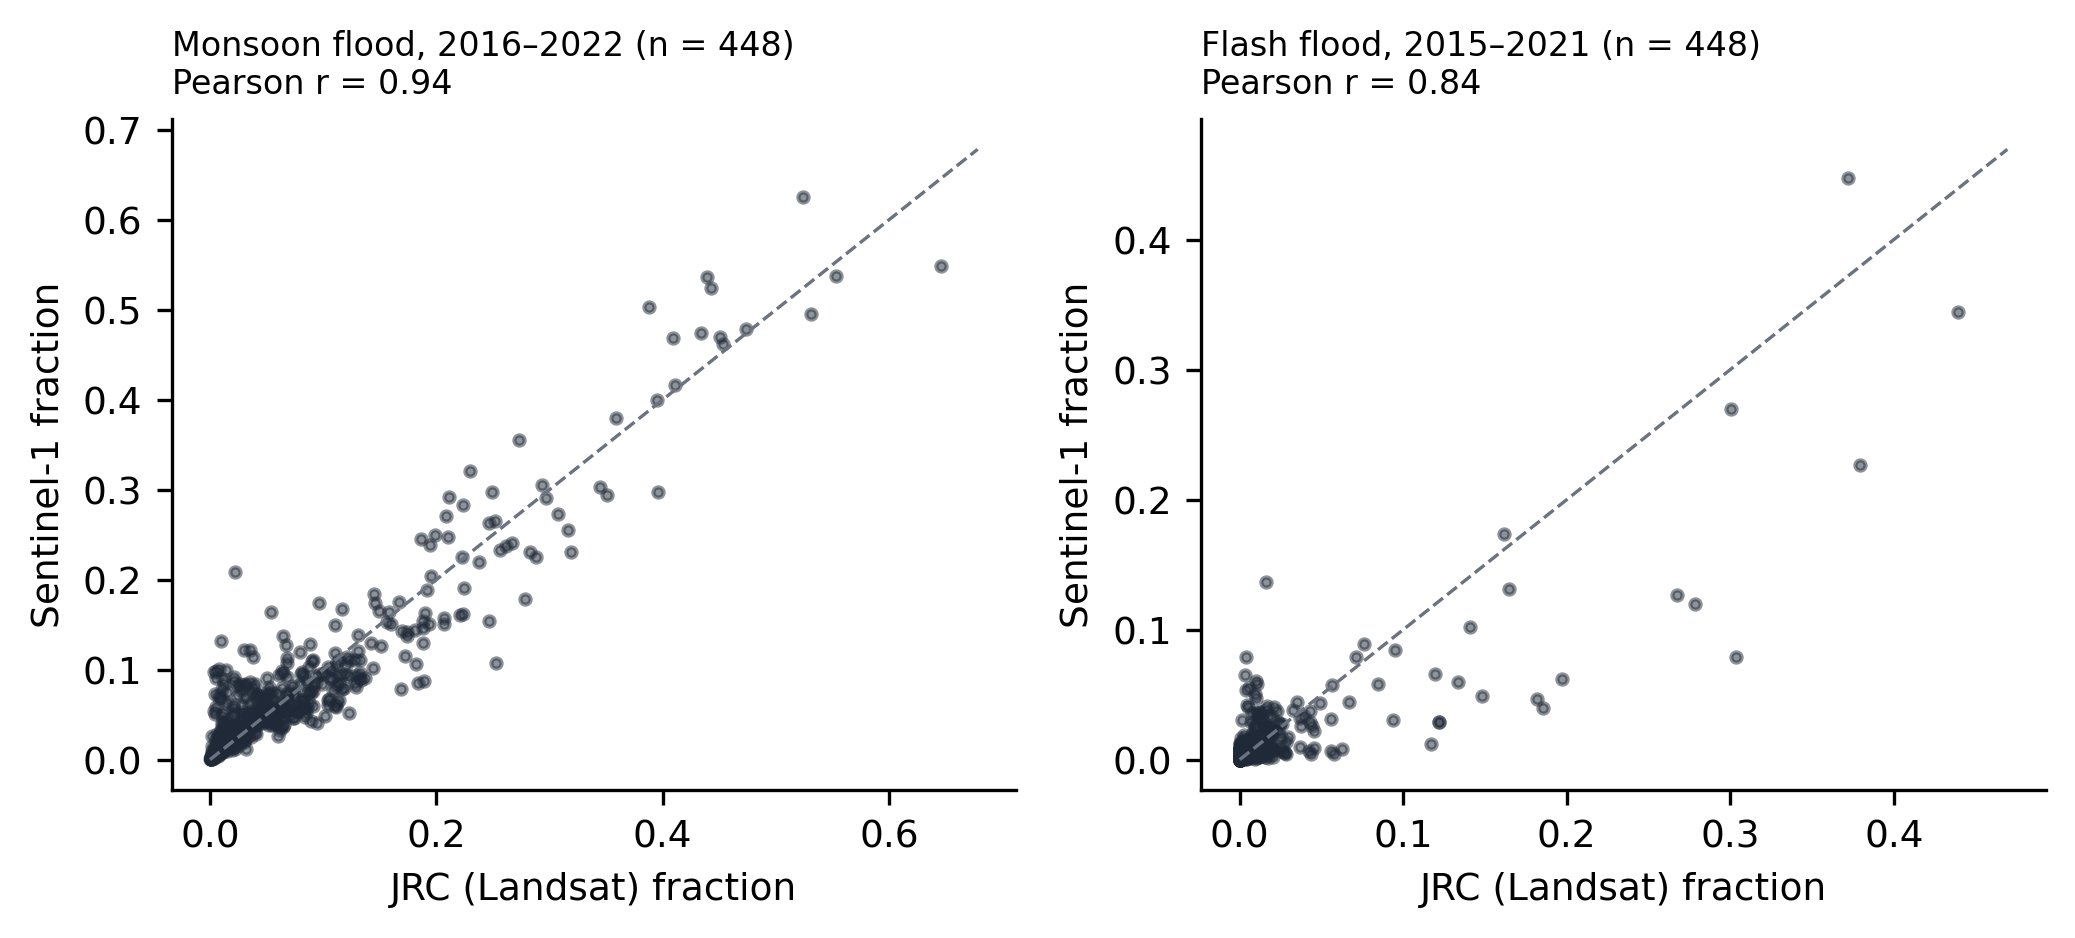

In [26]:
display(pd.read_csv(OUT / "tables" / "table_flood_agreement.csv"))
show("fig6_flood_agreement.png", width=800)

**Event-based check.** The April 2017 flash flood in the north-eastern haor basin should appear in the flood
fractions and in the BBS statistics of the affected districts. In the most affected districts the losses appear in
harvested area and production rather than in yield, because BBS reports yield per harvested hectare.

In [27]:
pd.read_csv(OUT / "tables" / "table_event_2017.csv").head(8).round(1)

,district,s1_flash_flood_pct,jrc_flash_flood_pct,area_change_pct,yield_change_pct,production_change_pct
0,Sunamganj,44.7,37.2,-71.5,-0.1,-71.5
1,Kishoreganj,27.0,30.0,-31.4,3.8,-28.7
2,Netrokona,17.4,16.2,-21.2,0.3,-21.0
3,Sylhet,12.7,26.7,-18.8,-0.3,-19.1
4,Habiganj,10.2,14.1,-14.8,-1.6,-16.2
5,Moulvibazar,8.4,9.5,-21.3,-0.2,-21.5
6,Lalmonirhat,7.9,0.4,-2.8,3.2,0.2
7,Brahmanbaria,5.8,5.7,-4.9,1.2,-3.8


## 14. Example application

To show that the Gold tables support a typical downstream analysis, a district vulnerability index combines five
components (low yield, production instability, monsoon and flash flood exposure, heat exposure), each min–max
normalised, with equal weights; weight sensitivity uses 10,000 random weightings, and spatial clustering is tested
with Moran's I and LISA. This is an illustration of use, not part of the evaluation of the framework (Appendix B of
the paper).

,rank,district,vi,mean_yield,monsoon_flood_mean,flash_flood_mean,hot_days_mean,cluster_005
0,1,Sunamganj,0.577712,3.788800,0.482160,0.163512,1.894270,HH
1,2,Patuakhali,0.463950,2.673067,0.024926,0.009343,7.572636,ns
2,3,Kishoreganj,0.459878,4.225067,0.465861,0.127251,6.657633,HH
3,4,Barguna,0.367627,3.055533,0.010118,0.004582,6.969424,ns
4,5,Sylhet,0.354327,3.069467,0.212638,0.071676,1.551039,HH
5,6,Brahmanbaria,0.317929,4.040267,0.300523,0.043164,8.889447,ns
6,7,Chapai Nawabganj,0.306749,4.077067,0.109515,0.001326,25.808336,ns
7,8,Habiganj,0.305840,3.657600,0.187377,0.061833,6.224597,HH
8,9,Netrokona,0.303768,4.148933,0.289347,0.071695,4.107918,HH
9,10,Meherpur,0.302979,3.995533,0.005870,0.000227,29.880051,ns


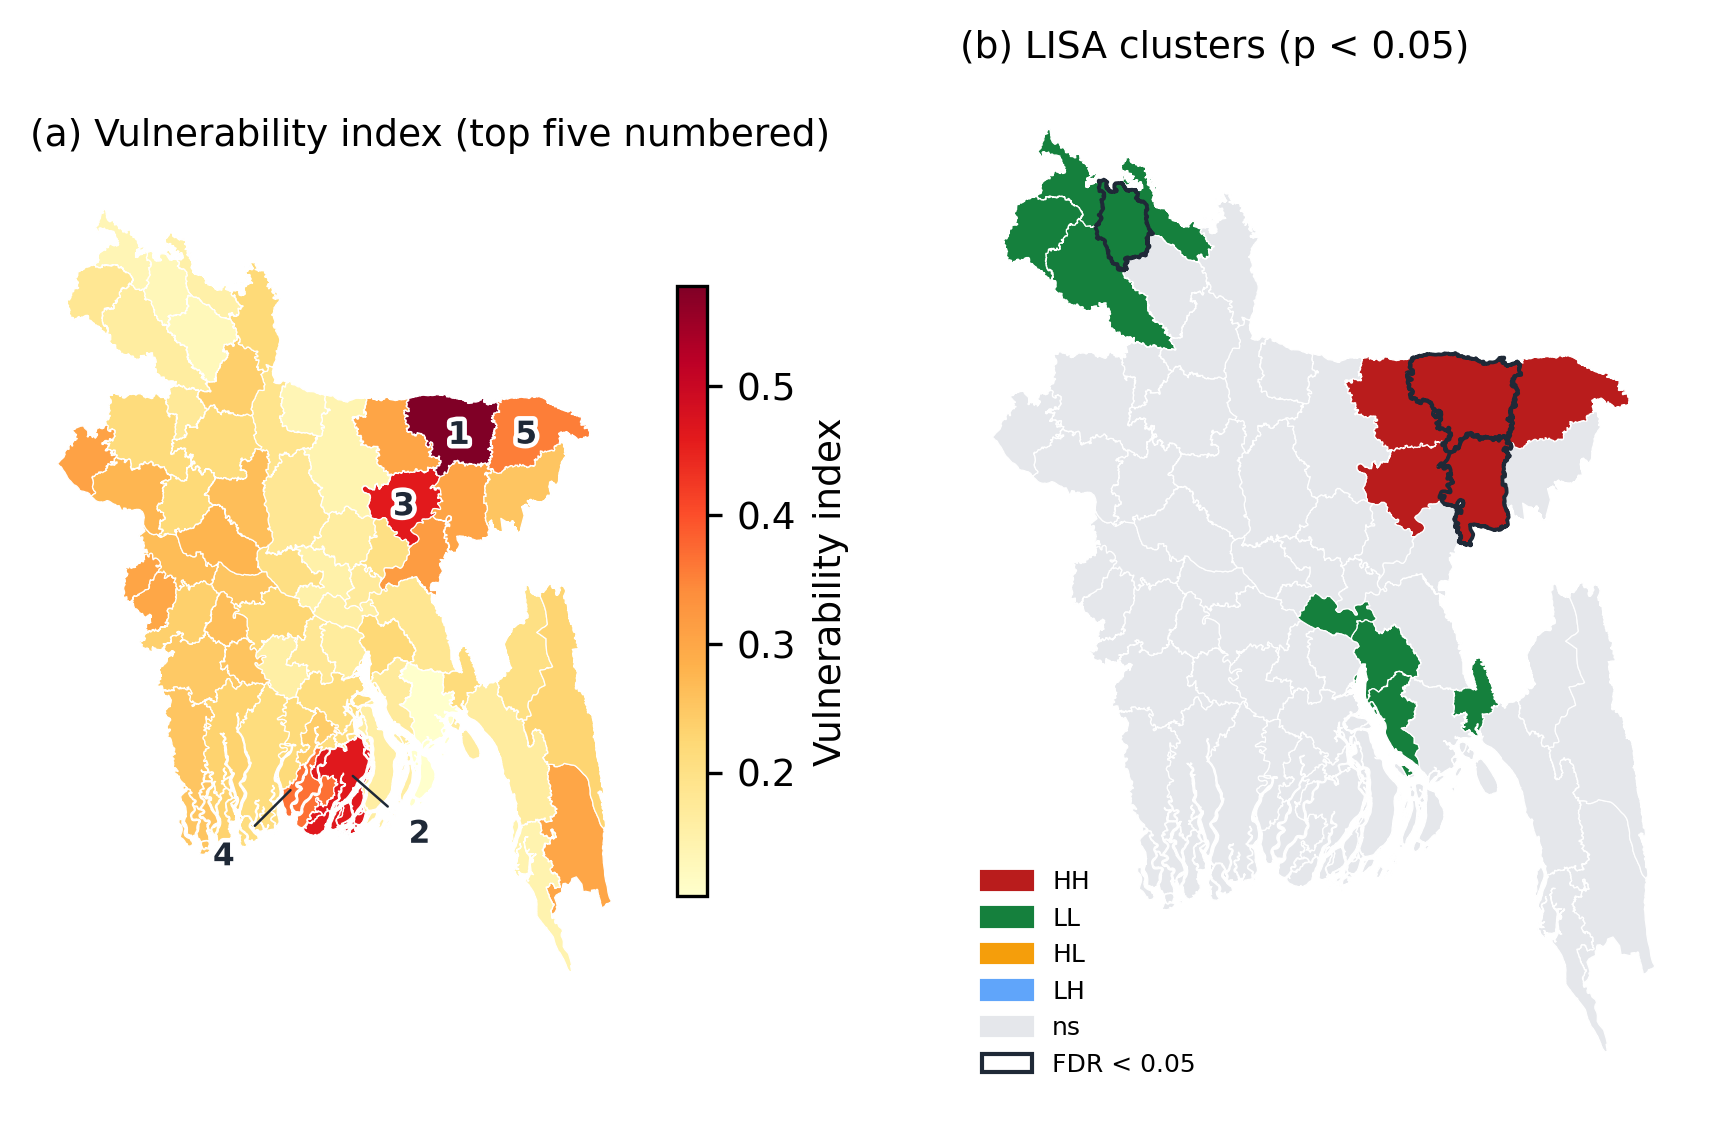

In [28]:
display(pd.read_csv(OUT / "tables" / "table_vulnerability_index.csv").head(10)[
    ["rank", "district", "vi", "mean_yield", "monsoon_flood_mean", "flash_flood_mean", "hot_days_mean", "cluster_005"]])
show("fig3_vulnerability_lisa.png", width=800)

## 15. Dashboard

A Streamlit dashboard reads the Gold tables and analysis outputs directly, so its figures cannot diverge from the
paper. It has a national overview, a district explorer, the index and cluster maps, and a data-quality page. Start it
from the repository root with:

```
streamlit run v2/dashboard_v2.py
```

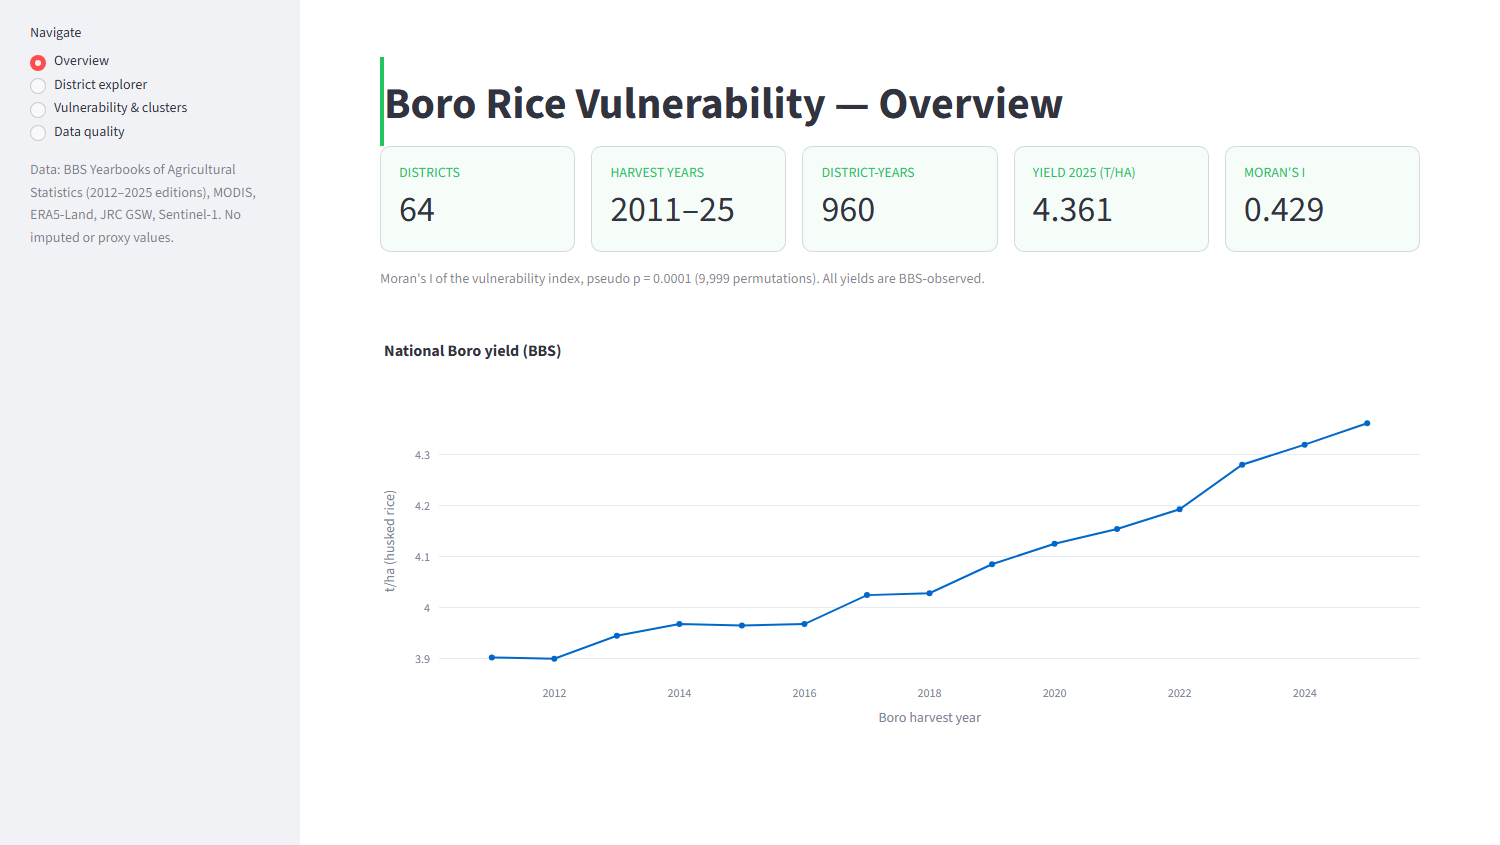

In [29]:
show("fig7_dashboard.png", width=900)

## 16. Rebuilding everything

From the repository root, after installing the pinned packages (`python -m pip install -r v2/requirements-lock.txt`)
and downloading the BBS yearbook PDFs and the GADM boundaries as described in `v2/README.md`:

```
python v2/run_all.py                          # the whole pipeline, about 3–5 minutes
python v2/tests/run_failure_tests.py          # the ten failure tests and the baseline, about 5 minutes
python v2/src/s06_manuscript.py paper_ems     # the manuscript, with the test results
python v2/tests/run_fresh_setup_test.py       # optional: reproducibility in two clean environments, about 45 minutes
```

The software versions used to produce the results are printed below; every package is pinned in
`requirements-lock.txt`.

In [30]:
import platform
from importlib.metadata import version
print("Python", platform.python_version())
for pkg in ["duckdb", "pandas", "numpy", "pyarrow", "camelot-py", "earthengine-api", "geopandas", "libpysal", "esda",
            "scipy", "statsmodels", "matplotlib", "streamlit"]:
    print(f"{pkg:16s} {version(pkg)}")

Python 3.13.7
duckdb           1.5.2
pandas           2.3.3
numpy            2.3.3
pyarrow          24.0.0
camelot-py       1.0.9
earthengine-api  1.7.22
geopandas        1.1.3
libpysal         4.14.1
esda             2.9.0
scipy            1.16.3
statsmodels      0.14.6
matplotlib       3.10.7
streamlit        1.58.0
